In [ ]:
#| default_exp voice

# A voice, taken apart

> Kokoro-82M, opened up: text to phonemes, phonemes to timed frames, frames to audio, and where every word lands.

This line of notebooks builds a reader with the controls audio-reader gives Apple's Alex voice: play, pause at a word,
seek, change speed, change voice, and highlight each word as it's spoken. Then it makes the voice fast on Apple and
Android hardware, and finally puts the two together.

We start with the voice: [Kokoro-82M](https://huggingface.co/hexgrad/Kokoro-82M), an open, Apache-licensed model.
Kokoro's own pipeline goes straight from text to audio. To control it we need to see inside, so in this notebook we
take it apart and put it back together, checking at the end that our version gives exactly the same audio.

In [ ]:
#| export
import re
from collections import namedtuple
from dataclasses import dataclass

import numpy as np
import torch
from kokoro import KModel, KPipeline

/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: invalid escape sequence '\.'
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.
W1101 22:08:32.052000 26101 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
W1101 22:08:32.089000 26101 .venv/lib/python3.13/site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1101 22:08:32.138000 26101 .venv/lib/python3.13/site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclas

In [ ]:
import matplotlib.pyplot as plt
from fastcore.test import test_close, test_eq
from IPython.display import Audio

## The black box

The model is about 82 million parameters, loaded once and shared. Kokoro's `KPipeline` wraps it with a frontend for
one language; the first letter of a voice's name says which (`a` for American English, `b` for British). Pipelines
are cheap, so we make them as needed, all sharing the one model.

In [ ]:
#| export
REPO = "hexgrad/Kokoro-82M"
SR = 24_000  # Kokoro's sample rate
FRAME = 600  # Samples per frame: Kokoro decides durations in 25 ms steps
model = KModel(repo_id=REPO).eval()
_pipelines = {}


def pipeline(voice="af_heart"):
    "Kokoro's pipeline for `voice`'s language, sharing the one model."
    lang = voice[0]
    if lang not in _pipelines:
        _pipelines[lang] = KPipeline(lang_code=lang, repo_id=REPO, model=model)
    return _pipelines[lang]

/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torch/nn/modules/rnn.py:1011: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)
/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


In [ ]:
text = "Doctor Smith paid $12.50 for 3 books on 1/2/2024, didn't she?"
torch.manual_seed(0)
(kokoro,) = pipeline()(text, voice="af_heart", split_pattern=None)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters")
Audio(kokoro.audio, rate=SR)

82M parameters


/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


That's the target. The model has five parts, and the last, the decoder, holds two thirds of the weights:

In [ ]:
for name, part in model.named_children():
    print(f"{name:<13} {sum(p.numel() for p in part.parameters()) / 1e6:5.1f}M")

bert            6.3M
bert_encoder    0.4M
predictor      16.2M
text_encoder    5.6M
decoder        53.3M


## Text to phonemes

First the frontend, misaki, turns text into phonemes. It works word by word, so it also gives us *tokens*: each word
with its phonemes and whether a space follows. Those tokens are what will let us find each word in the audio later.

In [ ]:
#| export
def phonemize(text, voice="af_heart"):
    "Kokoro's frontend: `text` to a phoneme string, and the tokens (words, with their phonemes) it came from."
    _, tokens = pipeline(voice).g2p(text)
    for t in tokens:
        t.phonemes = t.phonemes or ""
    return KPipeline.tokens_to_ps(tokens), tokens

In [ ]:
phonemes, tokens = phonemize(text)
print(phonemes)
[(t.text, t.phonemes) for t in tokens][:8]

dˈɑktəɹ smˈɪθ pˈAd twˈɛlv dˈɑləɹz ænd fˈɪfti sˈɛnts fɔɹ θɹˈi bˈʊks ˌɔn wˈʌn tˈu twˈɛnti twˈɛnti fˈɔɹ, dˈɪdᵊnt ʃi?


[('Doctor', 'dˈɑktəɹ'),
 ('Smith', 'smˈɪθ'),
 ('paid', 'pˈAd'),
 ('$', ''),
 ('12.50', 'twˈɛlv dˈɑləɹz ænd fˈɪfti sˈɛnts'),
 ('for', 'fɔɹ'),
 ('3', 'θɹˈi'),
 ('books', 'bˈʊks')]

Notice `$12.50` became "twelve dollars and fifty cents", attached to `12.50`, and `$` got no phonemes of its own. And
`1/2/2024` is read "one two twenty twenty four", which is wrong: the frontend is a problem in its own right. The
phoneme string is what Kokoro saw:

In [ ]:
test_eq(phonemes, kokoro.phonemes)

## Phonemes to timed frames

The model's first four parts work out *how* to say the phonemes. A BERT-like encoder reads them in context, and a
duration predictor decides how long each lasts, as a number of 25 ms frames. Each phoneme's features are then
repeated for that many frames (the alignment), and from those the model predicts a pitch curve (F0) and an energy
curve (N), two values per frame.

Every phoneme, including the spaces and the stress marks, gets at least one frame. That will matter in the next
notebook. `speed` divides the durations, which is how Kokoro speaks faster.

`analyse` is Kokoro's `forward_with_tokens` up to the decoder, keeping everything it works out in an `Utterance`.

In [ ]:
#| export
@dataclass
class Utterance:
    "Everything Kokoro decides about how to say `text`, before making any sound."

    text: str
    voice: str
    phonemes: str
    tokens: list  # misaki's tokens: words with their phonemes
    frames: torch.Tensor  # How many 25 ms frames each phoneme lasts, with a silence at each end
    asr: torch.Tensor  # (1, 512, frames) features for the decoder
    F0: torch.Tensor  # (1, 2 * frames) pitch, in Hz
    N: torch.Tensor  # (1, 2 * frames) energy
    style: torch.Tensor  # (1, 128) the voice's timbre


@torch.no_grad()
def analyse(text, voice="af_heart", speed=1):
    "Kokoro up to the decoder: phonemes, their durations, and the features, pitch and energy for every frame."
    phonemes, tokens = phonemize(text, voice)
    ref_s = pipeline(voice).load_voice(voice)[len(phonemes) - 1]  # A style vector chosen by length
    ids = torch.LongTensor([[0, *[model.vocab[p] for p in phonemes if p in model.vocab], 0]])
    n = ids.shape[1]
    lengths, mask = torch.tensor([n]), torch.zeros(1, n, dtype=torch.bool)
    s = ref_s[:, 128:]
    bert = model.bert_encoder(model.bert(ids, attention_mask=(~mask).int())).transpose(-1, -2)
    d = model.predictor.text_encoder(bert, s, lengths, mask)
    duration = torch.sigmoid(model.predictor.duration_proj(model.predictor.lstm(d)[0])).sum(-1).squeeze()
    frames = torch.round(duration / speed).clamp(min=1).long()
    aln = torch.zeros(1, n, int(frames.sum()))  # Which phoneme each frame belongs to
    aln[0, torch.repeat_interleave(torch.arange(n), frames), torch.arange(int(frames.sum()))] = 1
    F0, N = model.predictor.F0Ntrain(d.transpose(-1, -2) @ aln, s)
    asr = model.text_encoder(ids, lengths, mask) @ aln
    return Utterance(text, voice, phonemes, tokens, frames, asr, F0, N, ref_s[:, :128])

115 phonemes, 272 frames = 6.80s


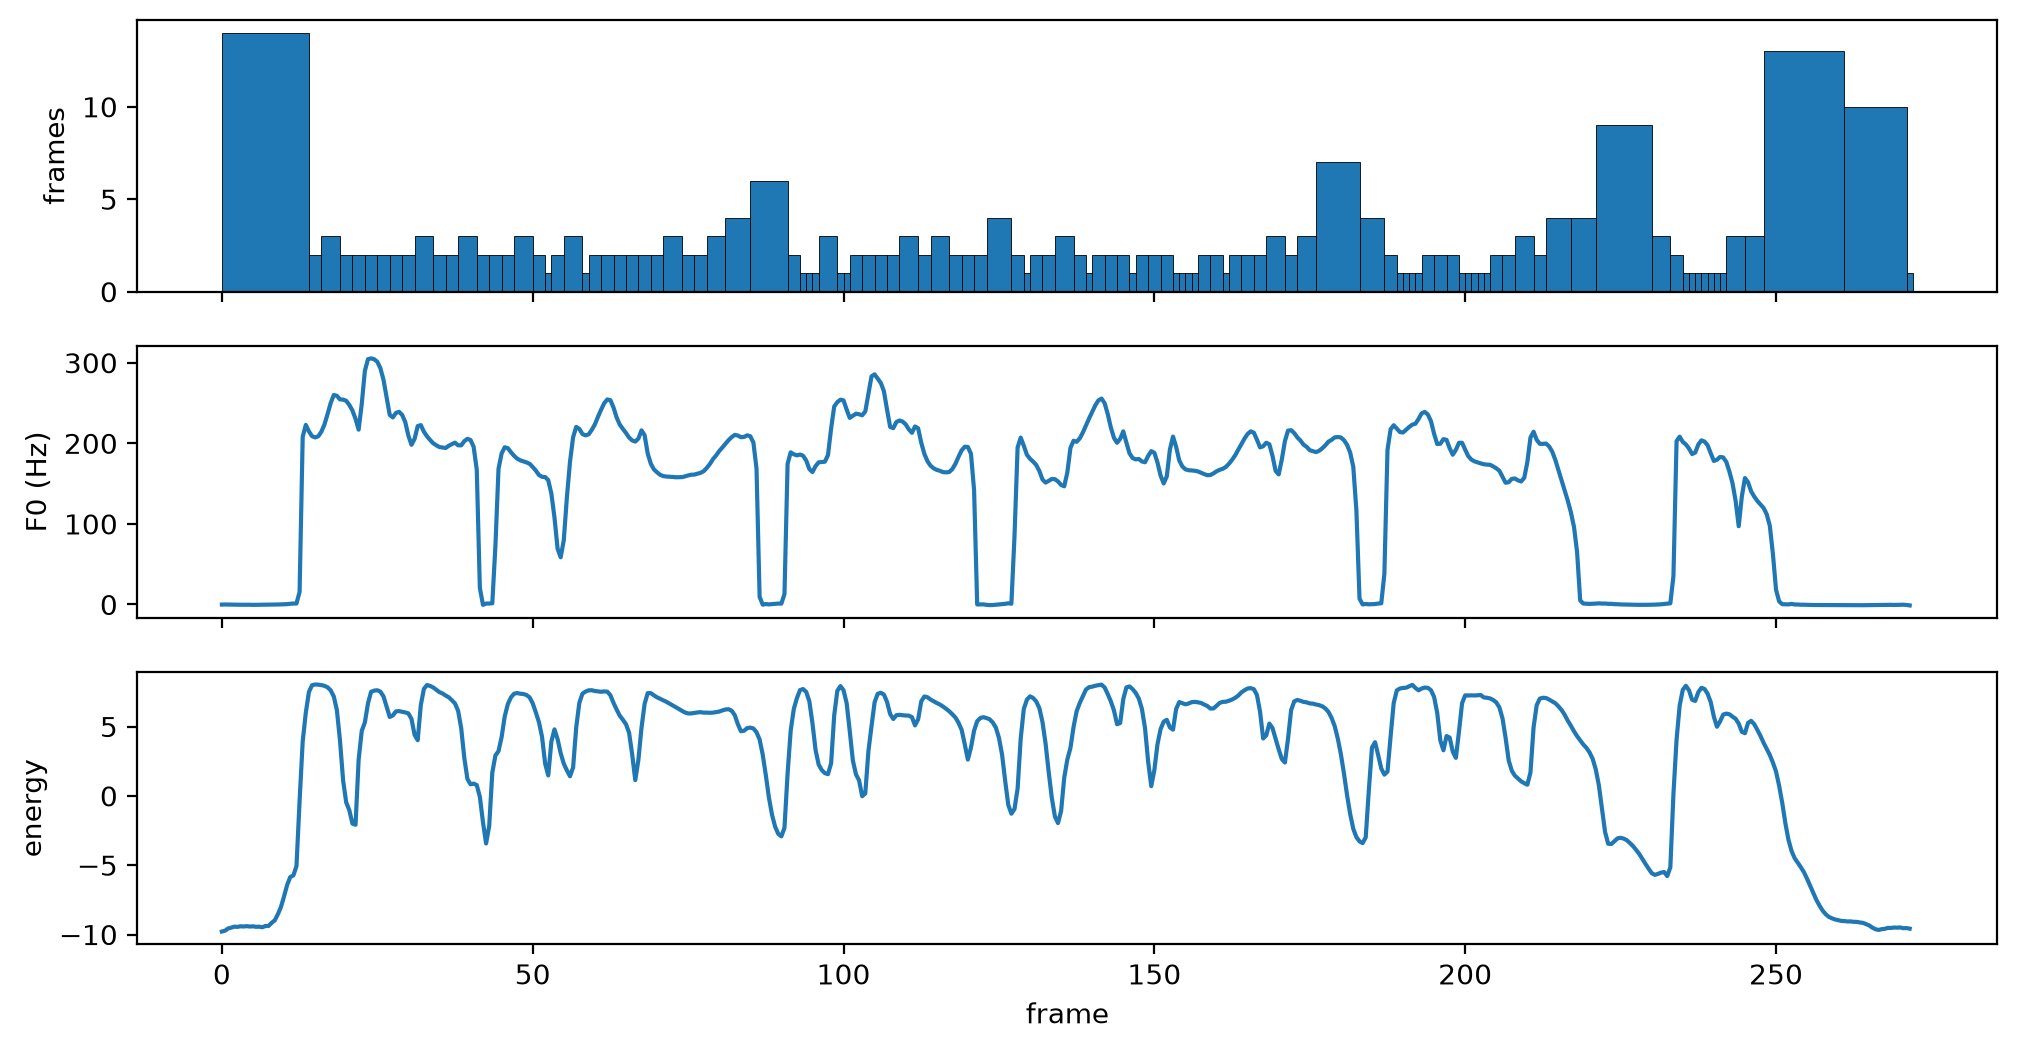

In [ ]:
u = analyse(text)
test_eq(u.frames, kokoro.pred_dur)
print(f"{len(u.frames)} phonemes, {int(u.frames.sum())} frames = {u.frames.sum() * FRAME / SR:.2f}s")
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
axes[0].bar(np.cumsum(u.frames) - u.frames / 2, u.frames, width=u.frames, edgecolor="k", lw=0.3)
axes[0].set_ylabel("frames")
axes[1].plot(np.arange(u.F0.shape[1]) / 2, u.F0[0])
axes[1].set_ylabel("F0 (Hz)")
axes[2].plot(np.arange(u.N.shape[1]) / 2, u.N[0])
axes[2].set_ylabel("energy")
axes[2].set_xlabel("frame")
plt.show()

The same durations Kokoro chose. Each bar is one phoneme; the pitch is zero where the speech is unvoiced or silent.

## Frames to audio

The decoder turns each frame's 512 features, with its pitch and energy, into 600 samples. It's a neural vocoder of the kind notebook 03
built, with a sine source driven by the pitch curve. Its source adds a little random noise, so to compare with Kokoro
we use the same seed.

In [ ]:
#| export
@torch.no_grad()
def decode(u):
    "Kokoro's decoder: an Utterance to audio, 600 samples per frame."
    return model.decoder(u.asr, u.F0, u.N, u.style).squeeze().numpy()

In [ ]:
torch.manual_seed(0)
audio = decode(u)
test_eq(len(audio), int(u.frames.sum()) * FRAME)
test_close(audio, kokoro.audio.numpy(), eps=1e-6)
Audio(audio, rate=SR)

Identical. We've rebuilt Kokoro from its parts, and now the parts are ours to swap.

## Where the words are

Since every frame belongs to a phoneme and every phoneme to a token, we know when every word starts and ends.
Kokoro's `join_timestamps` adds those times to the tokens. `words` turns them into positions in the text and in the
audio, skipping punctuation and anything that got no time (like `$`). This is the equivalent of the `willSpeakRange`
callback audio-reader gets from Alex, except we know it before playing.

In [ ]:
#| export
Word = namedtuple("Word", "text char_start char_end sample_start sample_end")


def words(u):
    "Every spoken word in `u`: where it is in the text, and where it is in the audio."
    KPipeline.join_timestamps(u.tokens, u.frames)
    out, i = [], 0
    for t in u.tokens:
        i = u.text.index(t.text, i)
        if t.start_ts is not None and re.search(r"\w", t.text):
            out.append(Word(t.text, i, i + len(t.text), round(t.start_ts * SR), round(t.end_ts * SR)))
        i += len(t.text)
    return out

In [ ]:
ws = words(u)
for w in ws:
    test_eq(text[w.char_start : w.char_end], w.text)
test_eq([w.sample_start for w in ws], sorted(w.sample_start for w in ws))
ws[:3]

[Word(text='Doctor', char_start=0, char_end=6, sample_start=6600, sample_end=16200),
 Word(text='Smith', char_start=7, char_end=12, sample_start=16200, sample_end=24600),
 Word(text='paid', char_start=13, char_end=17, sample_start=24600, sample_end=30600)]

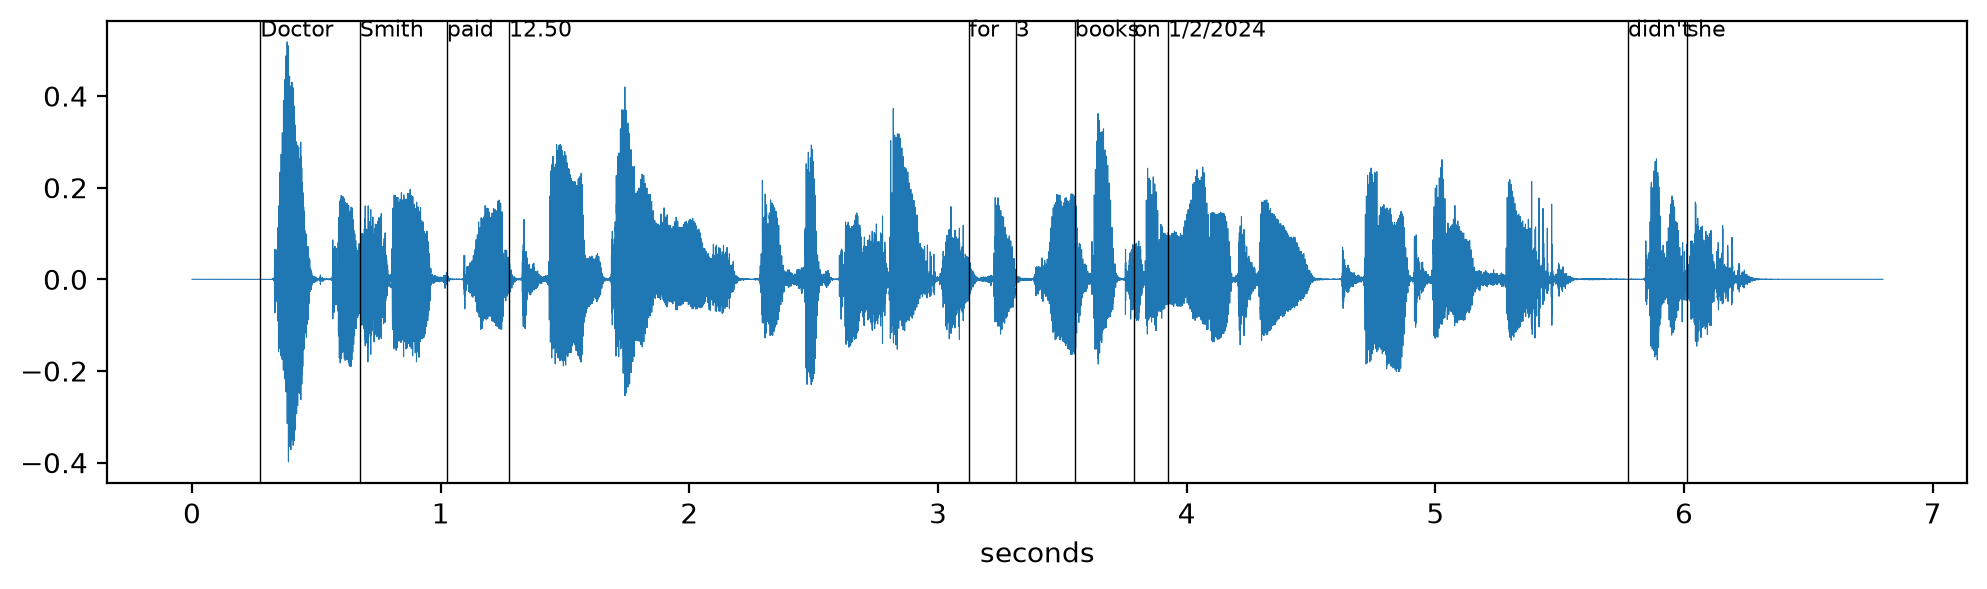

In [ ]:
plt.figure(figsize=(12, 3))
plt.plot(np.arange(len(audio)) / SR, audio, lw=0.4)
for w in ws:
    plt.axvline(w.sample_start / SR, color="k", lw=0.5)
    plt.text(w.sample_start / SR, audio.max(), w.text, fontsize=8, va="bottom")
plt.xlabel("seconds")
plt.show()

Cutting at a word's samples gives just that word:

In [ ]:
books = next(w for w in ws if w.text == "books")
Audio(audio[books.sample_start : books.sample_end], rate=SR)

## `say`

Putting it back together, with the decoder as an argument. Everything after this notebook is about that argument:
`decode` here is PyTorch on the CPU, and notebooks 103 and 104 make drop-in replacements that run on a Mac's GPU and
a phone's.

In [ ]:
#| export
def say(text, voice="af_heart", decoder=decode):
    "Speak `text`: returns the audio and where each word is in it."
    u = analyse(text, voice)
    return decoder(u), words(u)

In [ ]:
audio, ws = say("Every voice has a different style vector, and some a different frontend.", voice="bm_george")
print([w.text for w in ws])
Audio(audio, rate=SR)

['Every', 'voice', 'has', 'a', 'different', 'style', 'vector', 'and', 'some', 'a', 'different', 'frontend']


A British voice needed the British frontend, which `pipeline` made the first time it was asked for.

Kokoro has 54 voices in nine languages; the 28 English ones start `af`, `am`, `bf` and `bm` (female and male,
American and British). They're 0.5 MB each, because a voice is only a style vector per phoneme count: the model is
shared.

## Summary

- `phonemize`: text to phonemes, and tokens that remember which word each came from.
- `analyse`: phonemes to an `Utterance`, Kokoro's decisions about how to say them, in 25 ms frames.
- `decode`: an `Utterance` to audio.
- `words`: where every word is, in the text and the audio.
- `say`: all of it, with the decoder swappable.

Next: making it speak faster.